# Milestone 13 — Smartphone vs Laptop Cross-Category Evaluation

**Component 2:** Helpfulness-Guided Review Evidence Selection
with Minority Preservation

## Research Objective

Compare the preliminary smartphone and laptop
implementations using their saved experimental evidence.

## Evaluation Scope

1. Verify both categories' source artifacts.
2. Compare Function 1 held-out test results.
3. Harmonize Function 2 selector metrics.
4. Compare baseline and proposed selector behaviour.
5. Evaluate minority preservation and fidelity refinement.
6. Assess feasibility, repair swaps, and protected reviews.
7. Generate descriptive product-level bootstrap intervals.
8. Save PP1-ready tables, figures, and limitations.

## Interpretation Boundary

These are controlled development pilots, not independent
proof of generalization.

Both categories rely on synthetic C1 integration fixtures.
Some usefulness predictions are in-sample.

Function 1 models also differ in feature composition,
so their test scores are descriptive category results,
not a controlled model-transfer experiment.

Product-level bootstrap intervals quantify within-pilot
descriptive variability, not population-level certainty.

Protected-minority coverage and priority-minority
coverage are not treated as interchangeable.


## 1. Imports and Project Paths


In [1]:
from pathlib import Path
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_root(start):
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results").exists()
            and (candidate / "notebooks").exists()
        ):
            return candidate

    raise FileNotFoundError(
        "Component 2 project root not found."
    )


ROOT = find_root(Path.cwd().resolve())

SMART_EVAL = ROOT / "results" / "selector_evaluation"
SMART_REFINED = ROOT / "results" / "selector_refinement"

LAPTOP_STAGE_B = (
    ROOT / "results" / "selector"
    / "laptop" / "stage_b"
)

LAPTOP_F1 = (
    ROOT / "results" / "usefulness" / "laptop"
)

OUTPUT_DIR = ROOT / "results" / "cross_category"
TABLE_DIR = OUTPUT_DIR / "comparison_tables"
FIGURE_DIR = OUTPUT_DIR / "figures"
VALIDATION_DIR = OUTPUT_DIR / "validation"

for folder in [
    TABLE_DIR,
    FIGURE_DIR,
    VALIDATION_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)


PATHS = {
    "smartphone_baselines": (
        SMART_EVAL / "baseline_comparison_by_product.csv"
    ),
    "smartphone_evaluation_config": (
        SMART_EVAL / "evaluation_config.json"
    ),
    "smartphone_refinement": (
        SMART_REFINED / "fidelity_selector_comparison.csv"
    ),
    "smartphone_outcomes": (
        SMART_REFINED / "selector_refinement_outcomes.csv"
    ),
    "smartphone_refinement_config": (
        SMART_REFINED / "selector_refinement_config.json"
    ),
    "laptop_selector": (
        LAPTOP_STAGE_B / "laptop_selector_product_metrics.csv"
    ),
    "laptop_outcomes": (
        LAPTOP_STAGE_B / "laptop_fidelity_repair_summary.csv"
    ),
    "laptop_stage_b_config": (
        LAPTOP_STAGE_B / "laptop_stage_b_config.json"
    ),
    "laptop_f1_metrics": (
        LAPTOP_F1 / "laptop_test_metrics.csv"
    ),
    "laptop_f1_config": (
        LAPTOP_F1 / "laptop_model_config.json"
    ),
}


missing = {
    name: str(path)
    for name, path in PATHS.items()
    if not path.exists()
}

if missing:
    print("Missing evaluation artifacts:")
    for name, path in missing.items():
        print(f" - {name}: {path}")

    raise FileNotFoundError(
        "Required evidence is missing. "
        "Do not substitute invented metrics."
    )


def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))


smart_config = read_json(
    PATHS["smartphone_evaluation_config"]
)

smart_refined_config = read_json(
    PATHS["smartphone_refinement_config"]
)

laptop_config = read_json(
    PATHS["laptop_stage_b_config"]
)

laptop_f1_config = read_json(
    PATHS["laptop_f1_config"]
)

print("All required source artifacts found.")
print("Evaluation results:", OUTPUT_DIR)


All required source artifacts found.
Evaluation results: D:\Research\Repository\J26-DS-349\component_2\results\cross_category


## 2. Dataset and Evaluation Configuration Audit


In [2]:
smart_budget = int(smart_config["budget_k"])
laptop_budget = int(laptop_config["budget_k"])

smart_threshold = float(
    smart_refined_config["fidelity_threshold"]
)

laptop_threshold = float(
    laptop_config["fidelity_threshold"]
)

assert smart_budget == laptop_budget == 5

assert np.isclose(
    smart_threshold, laptop_threshold
)

assert np.isclose(smart_threshold, 0.35)

smart_weights = smart_config.get("full_weights", {})
laptop_weights = laptop_config["weights"]

for key in [
    "usefulness",
    "representativeness",
    "coverage",
    "minority",
    "redundancy",
]:
    if key in smart_weights:
        assert np.isclose(
            float(smart_weights[key]),
            float(laptop_weights[key]),
        ), f"Selector weight differs: {key}"


config_audit = pd.DataFrame([
    {
        "item": "Review budget",
        "smartphone": smart_budget,
        "laptop": laptop_budget,
        "compatible": True,
    },
    {
        "item": "Fidelity threshold",
        "smartphone": smart_threshold,
        "laptop": laptop_threshold,
        "compatible": True,
    },
    {
        "item": "C1 source",
        "smartphone": "Synthetic integration fixture",
        "laptop": "Synthetic integration fixture",
        "compatible": "Limited",
    },
    {
        "item": "Usefulness predictions",
        "smartphone": "Includes in-sample scores",
        "laptop": "Includes in-sample scores",
        "compatible": "Limited",
    },
    {
        "item": "Pilot reviews",
        "smartphone": 896,
        "laptop": 997,
        "compatible": "Different sample sizes",
    },
    {
        "item": "Pilot products",
        "smartphone": 10,
        "laptop": 10,
        "compatible": True,
    },
])

display(config_audit)

config_audit.to_csv(
    VALIDATION_DIR / "configuration_compatibility.csv",
    index=False,
)


,item,smartphone,laptop,compatible
0,Review budget,5,5,True
1,Fidelity threshold,0.35,0.35,True
2,C1 source,Synthetic integration fixture,Synthetic integration fixture,Limited
3,Usefulness predictions,Includes in-sample scores,Includes in-sample scores,Limited
4,Pilot reviews,896,997,Different sample sizes
5,Pilot products,10,10,True


## 3. Harmonize Function 2 Product-Level Metrics


In [3]:
smart_base = pd.read_csv(
    PATHS["smartphone_baselines"],
    dtype={"parent_asin": str},
)

smart_refined = pd.read_csv(
    PATHS["smartphone_refinement"],
    dtype={"product": str},
)

laptop = pd.read_csv(
    PATHS["laptop_selector"],
    dtype={"parent_asin": str},
)

COMMON_METRICS = [
    "mean_usefulness_norm",
    "mean_representativeness_norm",
    "aspect_coverage",
    "supported_minority_recall",
    "mean_pairwise_similarity",
    "opinion_js_divergence",
]

BASE_REQUIRED = {
    "parent_asin",
    "selector",
    "selected_count",
    *COMMON_METRICS,
}

assert BASE_REQUIRED.issubset(smart_base.columns)
assert BASE_REQUIRED.issubset(laptop.columns)

# The smartphone refinement file includes an __OVERALL__
# summary row, which must not be counted as another product.

smart_refined = smart_refined.loc[
    (smart_refined["product"] != "__OVERALL__")
    &
    (
        smart_refined["method"]
        == "FidelityAwareMinorityProtected"
    )
].copy()

assert len(smart_refined) == 10

smart_refined = smart_refined.rename(columns={
    "product": "parent_asin",
    "method": "selector",
    "mean_usefulness": "mean_usefulness_norm",
    "mean_representativeness": (
        "mean_representativeness_norm"
    ),
    "mean_pairwise_cosine_similarity": (
        "mean_pairwise_similarity"
    ),
    "opinion_jsd": "opinion_js_divergence",
})

smart_refined["selector"] = "FidelityRefined"

# Do not equate protected minority coverage to
# priority minority coverage. They refer to
# different denominators/definitions.

smart_refined["priority_minority_coverage"] = np.nan

smart_base["protected_minority_coverage"] = np.nan
laptop["protected_minority_coverage"] = np.nan

required_refined = BASE_REQUIRED - {"selector"}

assert required_refined.issubset(
    smart_refined.columns
)

smartphone_all = pd.concat(
    [smart_base, smart_refined],
    ignore_index=True,
    sort=False,
)

smartphone_all["category"] = "Smartphone"
laptop["category"] = "Laptop"

combined = pd.concat(
    [smartphone_all, laptop],
    ignore_index=True,
    sort=False,
)

EXPECTED_METHODS = {
    "ObservedHelpfulTopK",
    "PredictedUsefulnessTopK",
    "HelpfulnessMMR",
    "AspectCoverage",
    "ProposedNoMinority",
    "FullProposed",
    "FidelityRefined",
}

for category, frame in combined.groupby("category"):
    assert set(frame["selector"]) == EXPECTED_METHODS

    assert frame["parent_asin"].nunique() == 10
    assert len(frame) == 70

    assert frame.groupby(
        ["parent_asin", "selector"]
    ).size().eq(1).all()

    assert pd.to_numeric(
        frame["selected_count"]
    ).eq(5).all()

for metric in COMMON_METRICS:
    combined[metric] = pd.to_numeric(
        combined[metric],
        errors="raise",
    )

assert combined["aspect_coverage"].between(
    0, 1
).all()

assert combined[
    "opinion_js_divergence"
].between(0, 1).all()

assert combined[
    "mean_pairwise_similarity"
].between(-1, 1).all()

assert len(combined) == 140

HARMONIZED_PATH = (
    TABLE_DIR / "harmonized_selector_product_metrics.csv"
)

combined.to_csv(
    HARMONIZED_PATH,
    index=False,
)

print("Smartphone metric rows:", len(smartphone_all))
print("Laptop metric rows:", len(laptop))
print("Total product-level metric rows:", len(combined))
print("Harmonized selector metrics: PASS")


Smartphone metric rows: 70
Laptop metric rows: 70
Total product-level metric rows: 140
Harmonized selector metrics: PASS


## 4. Cross-Category Selector Summary


In [4]:
summary = (
    combined
    .groupby(
        ["category", "selector"],
        as_index=False,
    )
    .agg(
        products=("parent_asin", "nunique"),
        mean_usefulness=("mean_usefulness_norm", "mean"),
        mean_representativeness=(
            "mean_representativeness_norm", "mean"
        ),
        mean_aspect_coverage=("aspect_coverage", "mean"),
        mean_supported_minority_recall=(
            "supported_minority_recall", "mean"
        ),
        mean_pairwise_similarity=(
            "mean_pairwise_similarity", "mean"
        ),
        mean_opinion_jsd=(
            "opinion_js_divergence", "mean"
        ),
    )
)

assert len(summary) == 14
assert summary["products"].eq(10).all()

SUMMARY_PATH = (
    TABLE_DIR / "cross_category_selector_summary.csv"
)

summary.to_csv(
    SUMMARY_PATH,
    index=False,
)

display(summary.round(4))


,category,selector,products,mean_usefulness,mean_representativeness,mean_aspect_coverage,mean_supported_minority_recall,mean_pairwise_similarity,mean_opinion_jsd
0,Laptop,AspectCoverage,10,0.6642,0.7223,1.0000,0.4952,0.4324,0.2696
1,Laptop,FidelityRefined,10,0.6084,0.7849,0.9333,0.6706,0.4840,0.2431
2,Laptop,FullProposed,10,0.6402,0.7715,0.9444,0.6706,0.4704,0.2813
3,Laptop,HelpfulnessMMR,10,0.6946,0.6145,0.8472,0.5056,0.3257,0.3200
4,Laptop,ObservedHelpfulTopK,10,0.5654,0.7033,0.8264,0.3306,0.4229,0.3007
5,Laptop,PredictedUsefulnessTopK,10,0.7186,0.7316,0.8264,0.4623,0.4648,0.3024
6,Laptop,ProposedNoMinority,10,0.6875,0.7901,0.9000,0.4873,0.5007,0.2870
7,Smartphone,AspectCoverage,10,0.8512,0.7126,1.0000,0.3061,0.4752,0.2775
8,Smartphone,FidelityRefined,10,0.7116,0.7602,0.9500,0.4077,0.4805,0.2581
9,Smartphone,FullProposed,10,0.7427,0.7666,0.9333,0.4167,0.4926,0.3368


## 5. Full Proposed vs No-Minority Ablation


In [5]:
ablation_rows = []

for category in ["Smartphone", "Laptop"]:
    frame = summary.set_index(
        ["category", "selector"]
    )

    full = frame.loc[(category, "FullProposed")]
    no_minority = frame.loc[
        (category, "ProposedNoMinority")
    ]

    ablation_rows.append({
        "category": category,
        "full_supported_minority_recall": (
            full["mean_supported_minority_recall"]
        ),
        "no_minority_supported_recall": (
            no_minority["mean_supported_minority_recall"]
        ),
        "minority_recall_difference": (
            full["mean_supported_minority_recall"]
            - no_minority["mean_supported_minority_recall"]
        ),
        "full_usefulness": full["mean_usefulness"],
        "no_minority_usefulness": (
            no_minority["mean_usefulness"]
        ),
        "usefulness_difference": (
            full["mean_usefulness"]
            - no_minority["mean_usefulness"]
        ),
        "full_opinion_jsd": full["mean_opinion_jsd"],
        "no_minority_opinion_jsd": (
            no_minority["mean_opinion_jsd"]
        ),
    })

ablation_comparison = pd.DataFrame(ablation_rows)

display(ablation_comparison.round(4))

ablation_comparison.to_csv(
    TABLE_DIR / "cross_category_minority_ablation.csv",
    index=False,
)


,category,full_supported_minority_recall,no_minority_supported_recall,minority_recall_difference,full_usefulness,no_minority_usefulness,usefulness_difference,full_opinion_jsd,no_minority_opinion_jsd
0,Smartphone,0.4167,0.2811,0.1357,0.7427,0.8346,-0.0919,0.3368,0.2961
1,Laptop,0.6706,0.4873,0.1833,0.6402,0.6875,-0.0473,0.2813,0.2870


## 6. Fidelity-Refinement Comparison


In [6]:
fidelity_rows = []

for category in ["Smartphone", "Laptop"]:
    frame = summary.set_index(
        ["category", "selector"]
    )

    initial = frame.loc[(category, "FullProposed")]
    refined = frame.loc[(category, "FidelityRefined")]

    fidelity_rows.append({
        "category": category,
        "initial_mean_jsd": initial["mean_opinion_jsd"],
        "refined_mean_jsd": refined["mean_opinion_jsd"],
        "absolute_jsd_reduction": (
            initial["mean_opinion_jsd"]
            - refined["mean_opinion_jsd"]
        ),
        "relative_jsd_reduction_pct": (
            100 * (
                initial["mean_opinion_jsd"]
                - refined["mean_opinion_jsd"]
            ) / initial["mean_opinion_jsd"]
        ),
        "initial_minority_recall": (
            initial["mean_supported_minority_recall"]
        ),
        "refined_minority_recall": (
            refined["mean_supported_minority_recall"]
        ),
        "initial_usefulness": initial["mean_usefulness"],
        "refined_usefulness": refined["mean_usefulness"],
        "initial_redundancy": (
            initial["mean_pairwise_similarity"]
        ),
        "refined_redundancy": (
            refined["mean_pairwise_similarity"]
        ),
    })

fidelity_comparison = pd.DataFrame(fidelity_rows)

assert fidelity_comparison[
    "absolute_jsd_reduction"
].ge(-1e-10).all()

display(fidelity_comparison.round(4))

fidelity_comparison.to_csv(
    TABLE_DIR / "cross_category_fidelity_comparison.csv",
    index=False,
)


,category,initial_mean_jsd,refined_mean_jsd,absolute_jsd_reduction,relative_jsd_reduction_pct,initial_minority_recall,refined_minority_recall,initial_usefulness,refined_usefulness,initial_redundancy,refined_redundancy
0,Smartphone,0.3368,0.2581,0.0787,23.3700,0.4167,0.4077,0.7427,0.7116,0.4926,0.4805
1,Laptop,0.2813,0.2431,0.0382,13.5941,0.6706,0.6706,0.6402,0.6084,0.4704,0.4840


## 7. Repair Feasibility and Protected Review Retention


In [7]:
smart_outcomes = pd.read_csv(
    PATHS["smartphone_outcomes"],
    dtype={"product": str},
)

laptop_outcomes = pd.read_csv(
    PATHS["laptop_outcomes"],
    dtype={"parent_asin": str},
)

smart_outcomes = smart_outcomes.rename(columns={
    "product": "parent_asin",
    "locked_minority_review_count": "locked_reviews",
    "locked_review_retention": "locked_retention",
})

smart_outcomes["category"] = "Smartphone"
laptop_outcomes["category"] = "Laptop"

required_outcome_columns = {
    "parent_asin",
    "status",
    "initial_jsd",
    "final_jsd",
    "repair_swaps",
    "locked_reviews",
    "locked_retention",
}

assert required_outcome_columns.issubset(
    smart_outcomes.columns
)

assert required_outcome_columns.issubset(
    laptop_outcomes.columns
)

outcomes = pd.concat(
    [smart_outcomes, laptop_outcomes],
    ignore_index=True,
    sort=False,
)

assert len(outcomes) == 20

outcomes["initial_jsd"] = pd.to_numeric(
    outcomes["initial_jsd"]
)

outcomes["final_jsd"] = pd.to_numeric(
    outcomes["final_jsd"]
)

outcomes["repair_swaps"] = pd.to_numeric(
    outcomes["repair_swaps"]
)

for category, frame in outcomes.groupby("category"):
    assert frame["parent_asin"].nunique() == 10

outcome_summary = (
    outcomes.groupby("category", as_index=False)
    .agg(
        products=("parent_asin", "nunique"),
        total_repair_swaps=("repair_swaps", "sum"),
        mean_initial_jsd=("initial_jsd", "mean"),
        mean_final_jsd=("final_jsd", "mean"),
        mean_locked_retention=("locked_retention", "mean"),
        feasible_products=(
            "status",
            lambda x: int(
                x.isin(["feasible", "no_minority_required"])
                .sum()
            ),
        ),
        relaxed_products=(
            "status",
            lambda x: int((x == "relaxed").sum()),
        ),
        failed_products=(
            "status",
            lambda x: int((x == "failed").sum()),
        ),
    )
)

display(outcome_summary.round(4))

outcomes.to_csv(
    TABLE_DIR / "cross_category_fidelity_outcomes.csv",
    index=False,
)

outcome_summary.to_csv(
    TABLE_DIR / "cross_category_constraint_summary.csv",
    index=False,
)


,category,products,total_repair_swaps,mean_initial_jsd,mean_final_jsd,mean_locked_retention,feasible_products,relaxed_products,failed_products
0,Laptop,10,3,0.2813,0.2431,1.0,10,0,0
1,Smartphone,10,6,0.3368,0.2581,1.0,10,0,0


## 8. Function 1 Held-Out Test Comparison


In [8]:
laptop_test = pd.read_csv(
    PATHS["laptop_f1_metrics"]
)

selected_laptop_model = laptop_f1_config[
    "selected_model"
]

selected_laptop = laptop_test.loc[
    laptop_test["model"] == selected_laptop_model
]

assert len(selected_laptop) == 1

selected_laptop = selected_laptop.iloc[0]

# Smartphone values originate from the previously
# verified Function 1 execution (not a newly calculated
# result in this notebook).
#
# These values are explicitly labelled as reported evidence
# rather than claiming that a source CSV was reloaded.

function1_comparison = pd.DataFrame([
    {
        "category": "Smartphone",
        "test_reviews": 137,
        "mae": 0.5632,
        "rmse": 0.6655,
        "spearman": 0.3097,
        "ndcg_at_5": 0.5882,
        "ndcg_at_10": 0.6511,
        "model": "TF-IDF + Ridge (alpha=10)",
        "source_type": (
            "previously_verified_smartphone_notebook_03"
        ),
        "feature_note": "Review title and text",
    },
    {
        "category": "Laptop",
        "test_reviews": int(
            selected_laptop["review_count"]
        ),
        "mae": float(selected_laptop["mae"]),
        "rmse": float(selected_laptop["rmse"]),
        "spearman": float(
            selected_laptop["spearman"]
        ),
        "ndcg_at_5": float(
            selected_laptop["ndcg_at_5"]
        ),
        "ndcg_at_10": float(
            selected_laptop["ndcg_at_10"]
        ),
        "model": selected_laptop_model,
        "source_type": "saved_laptop_test_metrics_csv",
        "feature_note": (
            "Review text and numeric metadata"
        ),
    },
])

display(function1_comparison.round(4))

function1_comparison.to_csv(
    TABLE_DIR / "cross_category_function1_results.csv",
    index=False,
)

print(
    "Note: category test results are descriptive;"
    " feature configurations differ."
)


,category,test_reviews,mae,rmse,spearman,ndcg_at_5,ndcg_at_10,model,source_type,feature_note
0,Smartphone,137,0.5632,0.6655,0.3097,0.5882,0.6511,TF-IDF + Ridge (alpha=10),previously_verified_smartphone_notebook_03,Review title and text
1,Laptop,150,0.4267,0.5025,0.3223,0.5526,0.6834,text_metadata_alpha_10,saved_laptop_test_metrics_csv,Review text and numeric metadata


Note: category test results are descriptive; feature configurations differ.


## 9. Descriptive Product-Level Bootstrap Intervals


In [9]:
RANDOM_SEED = 42
BOOTSTRAP_RESAMPLES = 2000

rng = np.random.default_rng(RANDOM_SEED)


def bootstrap_mean_ci(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) < 2:
        return np.nan, np.nan, np.nan

    sampled = rng.choice(
        values,
        size=(BOOTSTRAP_RESAMPLES, len(values)),
        replace=True,
    )

    means = sampled.mean(axis=1)

    return (
        float(values.mean()),
        float(np.quantile(means, 0.025)),
        float(np.quantile(means, 0.975)),
    )


bootstrap_rows = []

for (category, selector), group in combined.groupby(
    ["category", "selector"]
):
    for metric in [
        "supported_minority_recall",
        "aspect_coverage",
        "opinion_js_divergence",
    ]:
        mean, low, high = bootstrap_mean_ci(
            group[metric].to_numpy()
        )

        bootstrap_rows.append({
            "category": category,
            "selector": selector,
            "metric": metric,
            "mean": mean,
            "ci95_lower": low,
            "ci95_upper": high,
            "product_count": group["parent_asin"].nunique(),
        })

bootstrap_table = pd.DataFrame(
    bootstrap_rows
)

assert len(bootstrap_table) == (
    2 * 7 * 3
)

bootstrap_table.to_csv(
    TABLE_DIR / "cross_category_bootstrap_intervals.csv",
    index=False,
)

display(
    bootstrap_table[
        bootstrap_table["selector"].isin(
            ["FullProposed", "FidelityRefined"]
        )
    ].round(4)
)

print(
    "Bootstrap intervals are descriptive within-pilot "
    "intervals, not a population-generalization claim."
)


,category,selector,metric,mean,ci95_lower,ci95_upper,product_count
3,Laptop,FidelityRefined,supported_minority_recall,0.6706,0.5595,0.7952,10
4,Laptop,FidelityRefined,aspect_coverage,0.9333,0.8778,0.9778,10
5,Laptop,FidelityRefined,opinion_js_divergence,0.2431,0.2078,0.2759,10
6,Laptop,FullProposed,supported_minority_recall,0.6706,0.5556,0.8072,10
7,Laptop,FullProposed,aspect_coverage,0.9444,0.9000,0.9889,10
8,Laptop,FullProposed,opinion_js_divergence,0.2813,0.2219,0.3465,10
24,Smartphone,FidelityRefined,supported_minority_recall,0.4077,0.3674,0.4495,10
25,Smartphone,FidelityRefined,aspect_coverage,0.9500,0.8667,1.0000,10
26,Smartphone,FidelityRefined,opinion_js_divergence,0.2581,0.2462,0.2716,10
27,Smartphone,FullProposed,supported_minority_recall,0.4167,0.3714,0.4566,10


Bootstrap intervals are descriptive within-pilot intervals, not a population-generalization claim.


## 10. Generate Comparative Figures


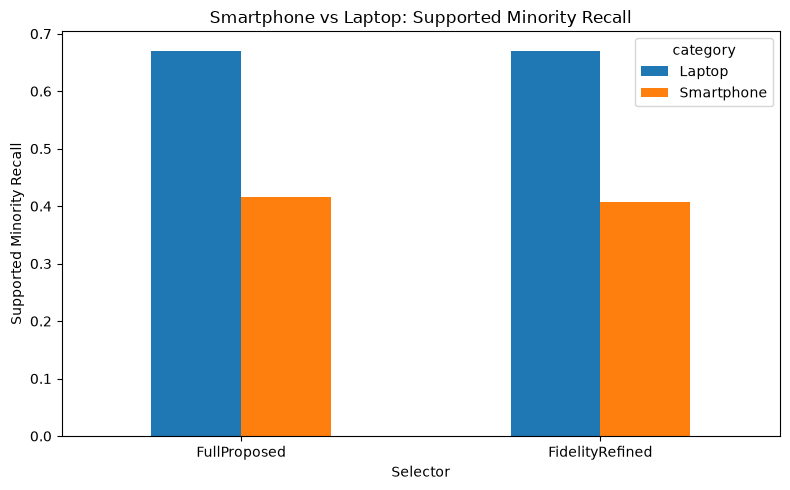

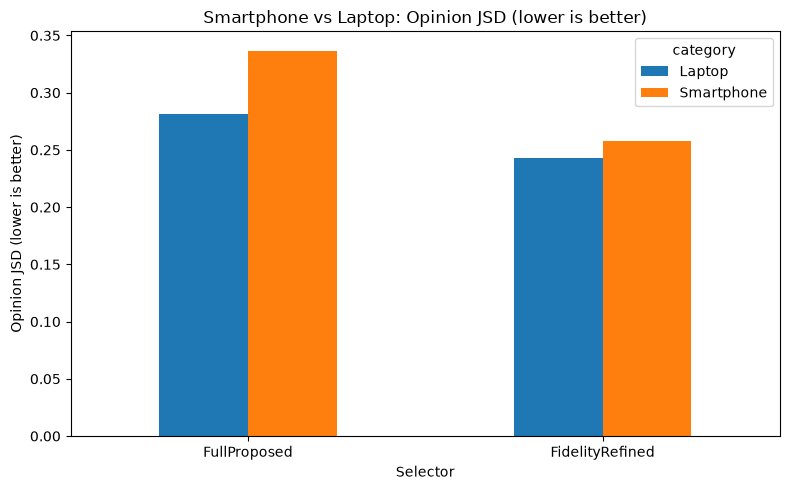

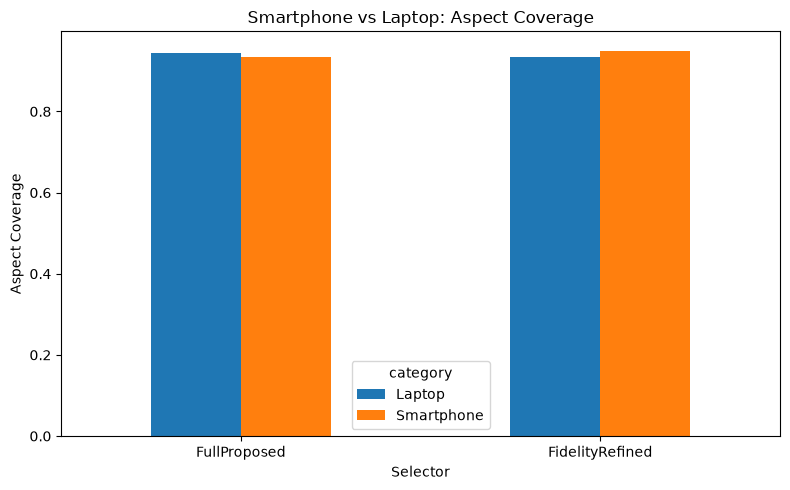

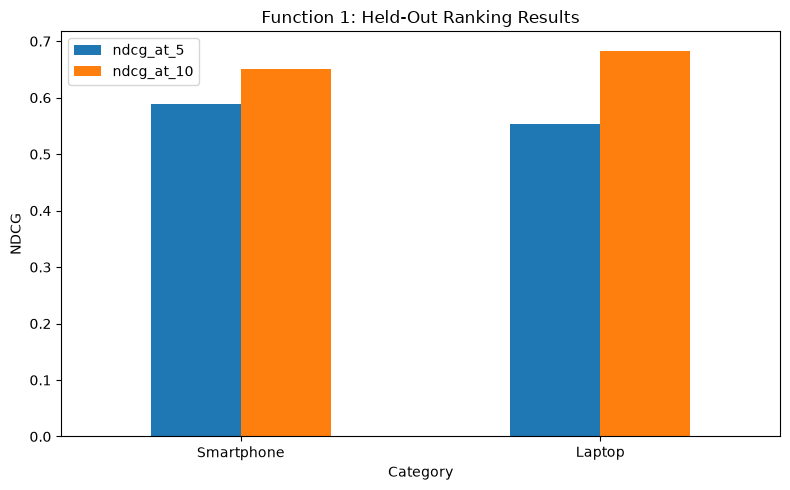

Comparison figures saved.


In [10]:
def grouped_metric_plot(metric, ylabel, filename):
    frame = summary[
        summary["selector"].isin(
            ["FullProposed", "FidelityRefined"]
        )
    ].copy()

    pivot = frame.pivot(
        index="selector",
        columns="category",
        values=metric,
    )

    pivot = pivot.reindex([
        "FullProposed",
        "FidelityRefined",
    ])

    ax = pivot.plot(
        kind="bar",
        figsize=(8, 5),
        rot=0,
    )

    ax.set_ylabel(ylabel)
    ax.set_xlabel("Selector")
    ax.set_title(
        f"Smartphone vs Laptop: {ylabel}"
    )

    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / filename,
        dpi=160,
        bbox_inches="tight",
    )
    plt.show()


grouped_metric_plot(
    "mean_supported_minority_recall",
    "Supported Minority Recall",
    "minority_recall_comparison.png",
)

grouped_metric_plot(
    "mean_opinion_jsd",
    "Opinion JSD (lower is better)",
    "opinion_fidelity_comparison.png",
)

grouped_metric_plot(
    "mean_aspect_coverage",
    "Aspect Coverage",
    "aspect_coverage_comparison.png",
)


f1_plot = function1_comparison.set_index(
    "category"
)[
    [
        "ndcg_at_5",
        "ndcg_at_10",
    ]
]

ax = f1_plot.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0,
)

ax.set_title("Function 1: Held-Out Ranking Results")
ax.set_ylabel("NDCG")
ax.set_xlabel("Category")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "function1_ndcg_comparison.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

print("Comparison figures saved.")


## 11. Save Evaluation Manifest and Validate


In [11]:
def sha256_file(path):
    digest = hashlib.sha256()

    with path.open("rb") as stream:
        for chunk in iter(
            lambda: stream.read(1024 * 1024),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


source_manifest = {
    name: {
        "relative_path": str(
            path.relative_to(ROOT)
        ),
        "sha256": sha256_file(path),
        "size_bytes": path.stat().st_size,
    }
    for name, path in PATHS.items()
}

manifest = {
    "milestone": 13,
    "categories": ["Smartphone", "Laptop"],
    "selector_variants": 7,
    "products_per_category": 10,
    "review_budget": 5,
    "fidelity_threshold": 0.35,
    "bootstrap_resamples": BOOTSTRAP_RESAMPLES,
    "bootstrap_seed": RANDOM_SEED,
    "source_files": source_manifest,
    "function1_smartphone_source": (
        "Previous verified smartphone Function 1 "
        "execution; figures manually transcribed "
        "from recorded results."
    ),
    "real_c1_integrated": False,
    "selector_evaluation_status": (
        "prototype_descriptive_cross_category"
    ),
    "metric_compatibility_notes": [
        "The two categories use synthetic C1 fixtures.",
        "Training-review usefulness scores include "
        "in-sample model predictions.",
        "Function 1 feature configurations differ.",
        "Protected minority coverage and priority "
        "minority coverage are not directly equated.",
        "Product-level bootstrap intervals are "
        "descriptive and do not prove generalization.",
        "No product-level cross-category pairing exists.",
    ],
}

MANIFEST_PATH = (
    VALIDATION_DIR / "cross_category_evaluation_manifest.json"
)

MANIFEST_PATH.write_text(
    json.dumps(
        manifest,
        indent=2,
    ),
    encoding="utf-8",
)

assert len(function1_comparison) == 2
assert len(combined) == 140
assert len(summary) == 14
assert len(outcomes) == 20
assert len(bootstrap_table) == 42

assert set(combined["category"]) == {
    "Smartphone",
    "Laptop",
}

assert combined.groupby(
    ["category", "selector"]
).size().eq(10).all()

assert all(path.exists() for path in [
    HARMONIZED_PATH,
    SUMMARY_PATH,
    TABLE_DIR / "cross_category_function1_results.csv",
    TABLE_DIR / "cross_category_minority_ablation.csv",
    TABLE_DIR / "cross_category_fidelity_comparison.csv",
    TABLE_DIR / "cross_category_constraint_summary.csv",
    TABLE_DIR / "cross_category_bootstrap_intervals.csv",
    MANIFEST_PATH,
])

print()
print(
    "Milestone 13 cross-category evaluation validation passed."
)
print("Categories: 2")
print("Products per category: 10")
print("Function 2 selector variants: 7")
print("Harmonized product-level metric rows:", len(combined))
print("Fidelity outcome rows:", len(outcomes))
print("Bootstrap interval rows:", len(bootstrap_table))
print("Real C1 integrated: False")
print("Evaluation status: Descriptive PP1 prototype")



Milestone 13 cross-category evaluation validation passed.
Categories: 2
Products per category: 10
Function 2 selector variants: 7
Harmonized product-level metric rows: 140
Fidelity outcome rows: 20
Bootstrap interval rows: 42
Real C1 integrated: False
Evaluation status: Descriptive PP1 prototype


## 12. Interpretation and Research Limitations

### What This Evaluation Can Establish

- Whether the implemented selector works in both pilots.
- How descriptive metrics vary between the categories.
- Whether supported-minority mechanisms operate in both.
- Whether fidelity repair maintains protected evidence.
- Whether both categories meet prototype constraints.

### What It Cannot Establish

- Statistically proven superiority across the entire
  smartphone or laptop populations.
- Unbiased selector quality under real C1 predictions.
- Strict model transfer or domain generalization.
- Causal effects of category differences.
- Equivalent calibration of synthetic C1 outputs.

### PP1 Reporting Guidance

Clearly distinguish:

1. Implemented functionality.
2. Preliminary descriptive comparison results.
3. Prototype limitations.
4. Future validation with real C1 evidence,
   out-of-fold usefulness predictions,
   and broader product samples.
